# 02 — Native 5-minute volatility dynamics

## Independence contract

This module starts from the native five-minute return series and does **not** consume Module 01 outputs or conclusions. It also consumes nothing from any other research branch.

The only database columns read are:

- `state_time`
- `underlying`
- `return_5m`

The primitive volatility object is exactly:

\[
v_t=r_t^2,
\]

where (r_t) is the single native five-minute return.

There is **no rolling 30m/60m block**, no HAR model, no clock adjustment inherited from elsewhere, no IV, no order book, no flow variable, and no latent-state label.

## Questions

1. What is the distribution of single-bar five-minute variance?
2. Is five-minute volatility persistent from one native bar to later native bars?
3. Does a large five-minute variance bar make another large bar more likely next?
4. Do extreme five-minute bars cluster into consecutive runs beyond the one-bar timescale?
5. How often do extreme five-minute bars occur simultaneously across assets?
6. Does the native five-minute series itself have deterministic UTC clock structure?


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 160)
pd.set_option('display.width', 260)
pd.set_option('display.max_rows', 400)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_dynamics_5m as vd5

START = os.getenv('VD5_START', '').strip() or None
END = os.getenv('VD5_END', '').strip() or None
ASSET_FILTER = [x.strip().upper() for x in os.getenv('VD5_ASSETS', '').split(',') if x.strip()]
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '02'
OUT.mkdir(parents=True, exist_ok=True)

print('volatility_dynamics_5m', vd5.VOLATILITY_DYNAMICS_5M_VERSION)
print('selftest:', vd5.selftest())
print('window:', START or 'earliest available', '->', END or 'latest available')


volatility_dynamics_5m 0.1.0
selftest: {'native_variance': True, 'timestamp_unit_normalization': True, 'lag_persistence': True, 'tail_episodes': True, 'quantile_transitions': True, 'gap_detection': True}
window: earliest available -> latest available


## 1. Load the native five-minute return series

No derived research feature is read from the database.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
available = set(con.execute('DESCRIBE time_series_feature_state').df()['column_name'])
required = {'state_time','underlying','return_5m'}
missing = sorted(required - available)
if missing:
    raise RuntimeError(f'time_series_feature_state lacks required columns: {missing}')

where = []
if START:
    where.append(f"state_time >= TIMESTAMPTZ '{pd.Timestamp(START, tz='UTC').isoformat()}'")
if END:
    end_ts = pd.Timestamp(END, tz='UTC') + pd.Timedelta(days=1)
    where.append(f"state_time < TIMESTAMPTZ '{end_ts.isoformat()}'")
if ASSET_FILTER:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSET_FILTER) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
df = con.execute(
    'SELECT state_time, underlying, return_5m FROM time_series_feature_state'
    + where_sql + ' ORDER BY underlying, state_time'
).df()
con.close()
df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
if df.empty:
    raise RuntimeError('No rows found.')
dupes = int(df.duplicated(['underlying','state_time']).sum())
if dupes:
    raise RuntimeError(f'Found {dupes} duplicate asset/timestamp rows.')
print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())}')
print(df.state_time.min(), '->', df.state_time.max())


rows 38,304 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-08 07:55:00+00:00


## 2. Build the five-minute volatility panel

For each row:

\[
v_t=r_t^2.
\]

`log_variance_5m` is only a numerical transform for scale compression; its epsilon is estimated independently per asset from that asset's own positive five-minute variance observations.


In [3]:
panels, metas = [], []
for asset, g in df.groupby('underlying', sort=True):
    p, meta = vd5.build_5m_panel(g)
    panels.append(p)
    metas.append(meta.__dict__)
panel = pd.concat(panels, ignore_index=True)
panel_meta = pd.DataFrame(metas)
display(panel_meta)


,underlying,inferred_bar_minutes,n_rows,n_finite_returns,finite_return_share,first_time,last_time,log_epsilon
0,AVAX,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,2.138583e-10
1,BTC,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,2.221356e-11
2,ETH,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,3.410561e-11
3,HYPE,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,1.131176e-10
4,SOL,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,7.368711e-11
5,TRX,5.0,5472,4714,0.861477,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,3.938506e-12
6,XRP,5.0,5472,4716,0.861842,2026-09-19 08:00:00+00:00,2026-10-08 07:55:00+00:00,1.005288e-10


## 3. Data coverage and missingness

Before studying persistence or duration, check whether missing returns are concentrated at particular UTC times or dates. A missing native bar breaks any consecutive-bar sequence.


In [4]:
missing_clock = vd5.missingness_by_clock(panel)
missing_date = vd5.missingness_by_date(panel)
display(panel_meta[['underlying','n_rows','n_finite_returns','finite_return_share']])
display(missing_date.sort_values(['underlying','coverage']).head(50))


,underlying,n_rows,n_finite_returns,finite_return_share
0,AVAX,5472,4716,0.861842
1,BTC,5472,4716,0.861842
2,ETH,5472,4716,0.861842
3,HYPE,5472,4716,0.861842
4,SOL,5472,4716,0.861842
5,TRX,5472,4714,0.861477
6,XRP,5472,4716,0.861842


,underlying,utc_date,n_rows,n_finite,coverage
0,AVAX,2026-09-19,192,0,0.000000
1,AVAX,2026-09-20,288,0,0.000000
2,AVAX,2026-09-21,288,158,0.548611
16,AVAX,2026-10-05,288,270,0.937500
12,AVAX,2026-10-01,288,274,0.951389
3,AVAX,2026-09-22,288,276,0.958333
11,AVAX,2026-09-30,288,276,0.958333
19,AVAX,2026-10-08,96,92,0.958333
9,AVAX,2026-09-28,288,277,0.961806
17,AVAX,2026-10-06,288,277,0.961806


## 4. Distribution of native five-minute variance

No smoothing or temporal aggregation is used.


,underlying,n,mean,std,q00,q01,q10,q25,median,q75,q90,q95,q99,max,mean_to_median
0,AVAX,4716,8.645164e-06,2.440152e-05,0.0,0.000000e+00,7.359500e-08,4.108580e-07,2.079852e-06,7.732371e-06,2.099304e-05,3.376964e-05,0.000099,0.000530,4.156624
1,BTC,4716,1.118740e-06,3.758581e-06,0.0,3.600000e-11,5.847000e-09,4.168600e-08,2.221360e-07,8.470540e-07,2.424093e-06,4.737809e-06,0.000014,0.000126,5.036291
2,ETH,4716,1.667822e-06,6.716531e-06,0.0,5.500000e-11,9.340000e-09,6.373800e-08,3.401940e-07,1.279633e-06,3.663092e-06,6.605669e-06,0.000019,0.000277,4.902569
3,HYPE,4716,3.944538e-06,9.675358e-06,0.0,4.610000e-10,3.375700e-08,2.291650e-07,1.123738e-06,3.824039e-06,9.864598e-06,1.613550e-05,0.000042,0.000220,3.510194
4,SOL,4716,3.063615e-06,1.098400e-05,0.0,1.490000e-10,2.248600e-08,1.495680e-07,7.345810e-07,2.507653e-06,6.626309e-06,1.218775e-05,0.000035,0.000457,4.170561
5,TRX,4714,2.132320e-07,7.673880e-07,0.0,9.000000e-12,8.830000e-10,6.277000e-09,3.898900e-08,1.619800e-07,4.713060e-07,8.706390e-07,0.000003,0.000030,5.469068
6,XRP,4716,4.606218e-06,1.472617e-05,0.0,0.000000e+00,1.818400e-08,1.918020e-07,9.749540e-07,3.637814e-06,1.043539e-05,1.882601e-05,0.000054,0.000356,4.724547


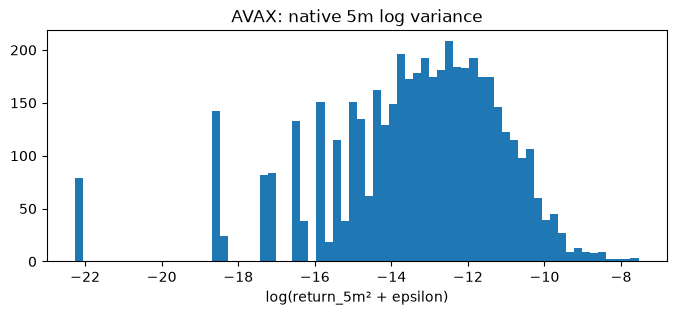

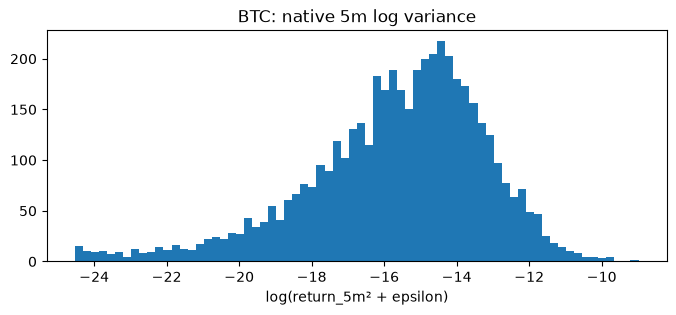

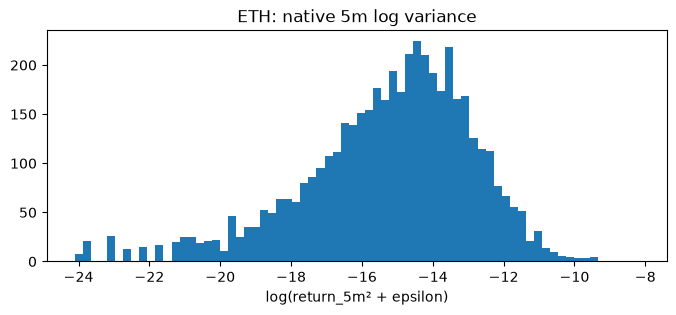

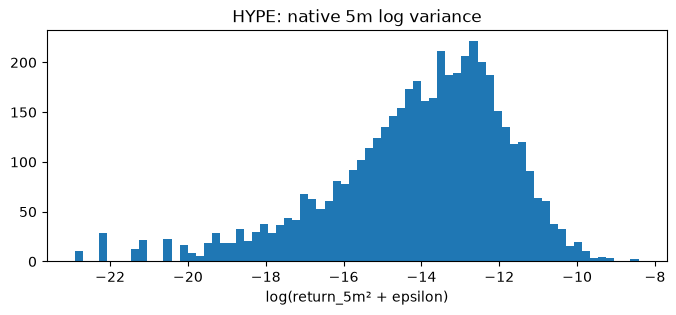

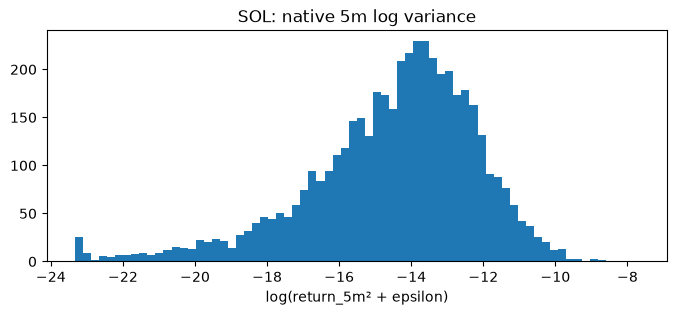

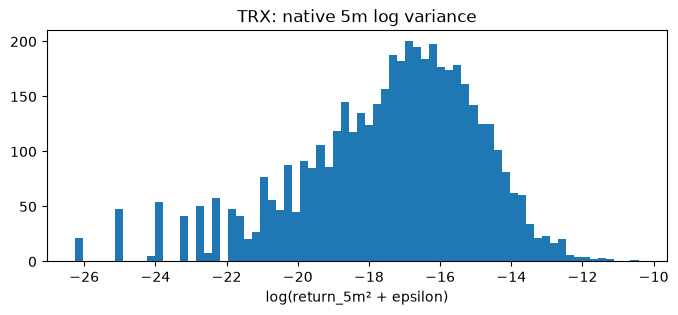

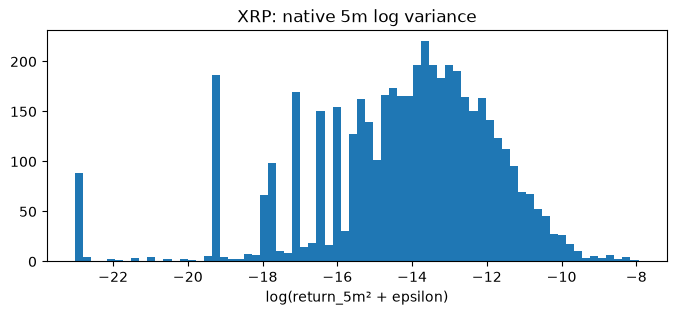

In [5]:
dist = vd5.distribution_summary(panel)
display(dist.round(12))

for asset in sorted(panel.underlying.unique()):
    x = panel.loc[panel.underlying == asset, 'log_variance_5m'].dropna()
    if len(x):
        fig, ax = plt.subplots(figsize=(8,3))
        ax.hist(x, bins=70)
        ax.set_title(f'{asset}: native 5m log variance')
        ax.set_xlabel('log(return_5m² + epsilon)')
        plt.show()


## 5. Native five-minute clock structure

This is measured here rather than assumed. Each exact UTC five-minute slot is compared only through the single-bar variance observed at that slot.


,underlying,n_clock_slots,clock_q10,clock_q90,clock_amplitude_q90_q10,pooled_log_variance_iqr,amplitude_to_pooled_iqr
0,AVAX,288,-14.0514,-12.1870,1.8644,2.9344,0.6354
1,BTC,288,-16.2979,-14.2293,2.0686,3.0111,0.6870
2,ETH,288,-15.9835,-13.9545,2.0289,2.9990,0.6765
3,HYPE,288,-14.5859,-12.8425,1.7434,2.8142,0.6195
4,SOL,288,-15.1404,-13.2275,1.9129,2.8189,0.6786
5,TRX,288,-18.2246,-16.0905,2.1341,3.2499,0.6567
6,XRP,288,-14.7918,-12.8896,1.9022,2.9422,0.6465


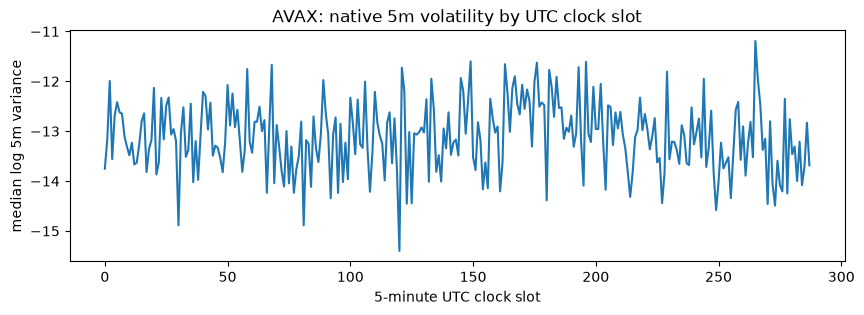

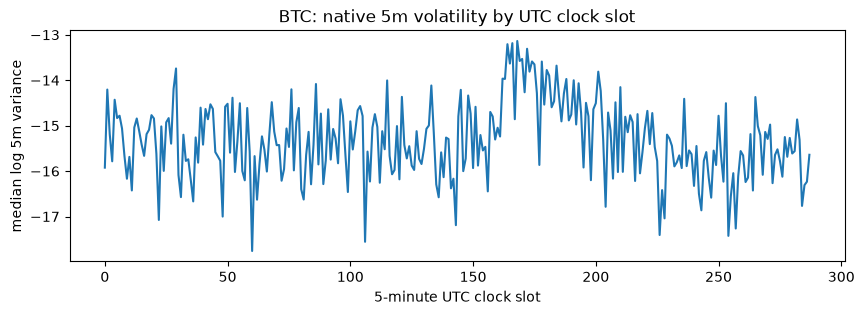

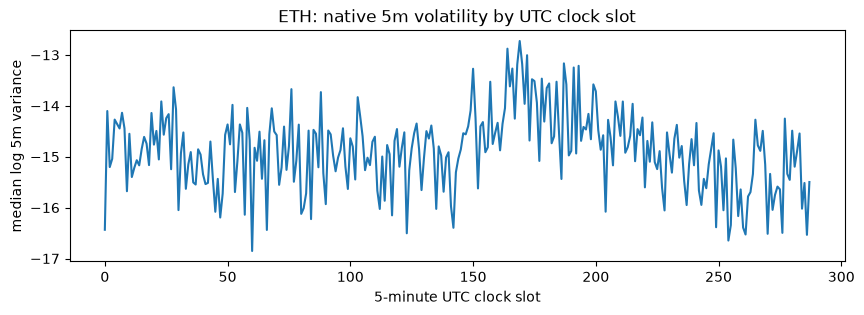

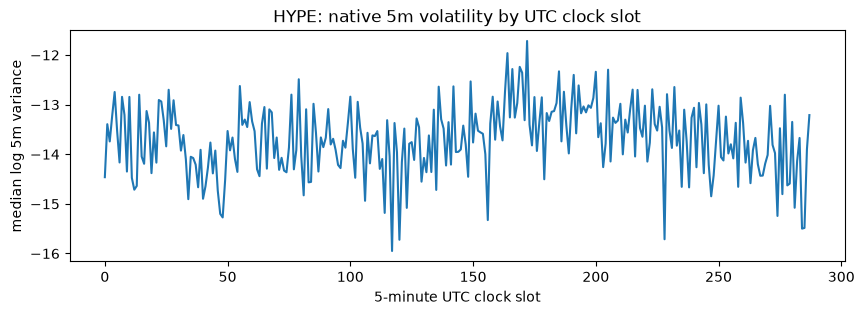

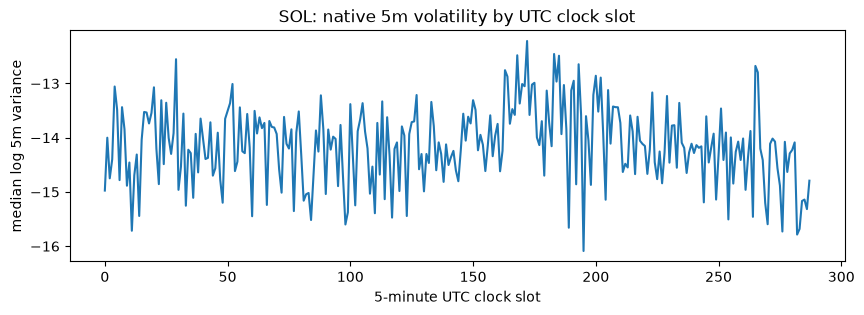

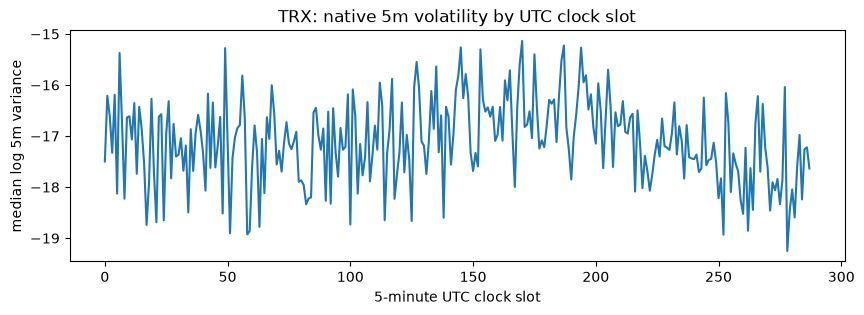

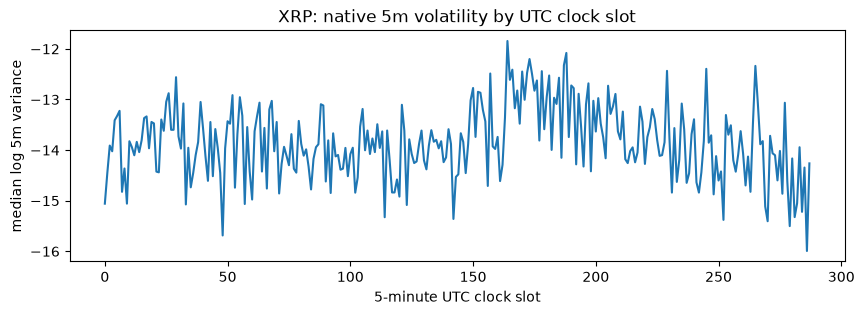

In [6]:
clock_profile, clock_summary = vd5.clock_profile(panel)
display(clock_summary.round(4))

for asset in sorted(panel.underlying.unique()):
    g = clock_profile[clock_profile.underlying == asset].sort_values('clock_slot')
    if len(g):
        fig, ax = plt.subplots(figsize=(10,3))
        ax.plot(g.clock_slot, g['median'])
        ax.set_title(f'{asset}: native 5m volatility by UTC clock slot')
        ax.set_xlabel('5-minute UTC clock slot')
        ax.set_ylabel('median log 5m variance')
        plt.show()


## 6. Five-minute volatility persistence

We correlate one native bar's log variance with later **native bars** at exact timestamp lags. A 30-minute lag here means six five-minute bars apart; it does **not** mean a 30-minute realized-variance block.


In [7]:
persistence = vd5.lag_persistence(panel)
display(persistence.pivot(index='underlying', columns='lag_minutes', values='spearman_log_variance').round(3))
display(persistence.pivot(index='underlying', columns='lag_minutes', values='pearson_log_variance').round(3))


lag_minutes,5,10,15,30,60,120,240
underlying,,,,,,,
AVAX,0.180,0.136,0.145,0.140,0.124,0.103,0.105
BTC,0.219,0.183,0.211,0.206,0.195,0.173,0.102
ETH,0.214,0.198,0.207,0.202,0.189,0.155,0.118
HYPE,0.158,0.158,0.151,0.142,0.130,0.110,0.078
SOL,0.161,0.152,0.142,0.157,0.124,0.103,0.101
TRX,0.145,0.119,0.098,0.078,0.053,0.083,0.077
XRP,0.221,0.204,0.208,0.215,0.214,0.165,0.168


lag_minutes,5,10,15,30,60,120,240
underlying,,,,,,,
AVAX,0.154,0.110,0.129,0.102,0.089,0.082,0.084
BTC,0.203,0.176,0.193,0.191,0.163,0.150,0.092
ETH,0.172,0.168,0.175,0.182,0.154,0.137,0.112
HYPE,0.134,0.131,0.123,0.119,0.109,0.100,0.059
SOL,0.136,0.113,0.099,0.130,0.091,0.070,0.076
TRX,0.145,0.121,0.081,0.071,0.051,0.076,0.064
XRP,0.171,0.158,0.166,0.170,0.176,0.137,0.133


## 7. One-step volatility-quantile transitions

Each asset's observed five-minute variance is ranked into ten empirical bins. We estimate the transition matrix from bar (t) to the immediately following five-minute bar (t+1), requiring an exact five-minute timestamp step.


In [8]:
transitions = vd5.quantile_transition_matrix(panel, n_bins=10)
for asset in sorted(panel.underlying.unique()):
    g = transitions[transitions.underlying == asset]
    mat = g.pivot(index='from_bin', columns='to_bin', values='probability')
    print('\n', asset)
    display(mat.round(3))



 AVAX


to_bin,1,2,3,4,5,6,7,8,9,10
from_bin,,,,,,,,,,
1,0.146,0.127,0.120,0.114,0.095,0.099,0.090,0.082,0.058,0.069
2,0.092,0.120,0.127,0.090,0.101,0.105,0.101,0.101,0.101,0.062
3,0.110,0.119,0.117,0.113,0.108,0.097,0.095,0.104,0.071,0.065
4,0.149,0.084,0.104,0.121,0.104,0.076,0.087,0.102,0.100,0.074
5,0.104,0.106,0.119,0.121,0.114,0.112,0.089,0.093,0.065,0.078
6,0.096,0.103,0.090,0.101,0.128,0.081,0.120,0.079,0.113,0.088
7,0.116,0.088,0.112,0.082,0.109,0.092,0.112,0.097,0.105,0.088
8,0.065,0.101,0.082,0.120,0.062,0.101,0.123,0.120,0.112,0.114
9,0.062,0.079,0.079,0.090,0.088,0.127,0.086,0.127,0.127,0.135



 BTC


to_bin,1,2,3,4,5,6,7,8,9,10
from_bin,,,,,,,,,,
1,0.150,0.120,0.097,0.112,0.114,0.112,0.090,0.079,0.058,0.069
2,0.128,0.135,0.145,0.100,0.098,0.098,0.079,0.088,0.068,0.060
3,0.166,0.135,0.116,0.110,0.088,0.088,0.080,0.088,0.071,0.058
4,0.116,0.109,0.094,0.105,0.094,0.088,0.122,0.101,0.084,0.086
5,0.075,0.101,0.129,0.120,0.099,0.114,0.101,0.097,0.090,0.073
6,0.076,0.086,0.076,0.117,0.121,0.130,0.112,0.112,0.099,0.071
7,0.091,0.108,0.091,0.091,0.101,0.110,0.106,0.110,0.101,0.093
8,0.073,0.092,0.105,0.092,0.124,0.075,0.099,0.116,0.122,0.101
9,0.077,0.060,0.086,0.101,0.094,0.101,0.103,0.101,0.131,0.148



 ETH


to_bin,1,2,3,4,5,6,7,8,9,10
from_bin,,,,,,,,,,
1,0.121,0.110,0.116,0.114,0.147,0.103,0.110,0.060,0.065,0.054
2,0.129,0.125,0.103,0.116,0.121,0.095,0.116,0.088,0.058,0.047
3,0.133,0.114,0.124,0.097,0.107,0.105,0.099,0.094,0.082,0.045
4,0.124,0.109,0.128,0.092,0.111,0.071,0.105,0.088,0.096,0.075
5,0.097,0.150,0.088,0.116,0.086,0.118,0.092,0.099,0.082,0.073
6,0.088,0.122,0.118,0.096,0.109,0.109,0.094,0.079,0.077,0.109
7,0.098,0.098,0.092,0.103,0.103,0.105,0.103,0.105,0.105,0.090
8,0.085,0.072,0.111,0.115,0.087,0.117,0.078,0.119,0.104,0.113
9,0.069,0.063,0.063,0.076,0.065,0.099,0.102,0.138,0.153,0.173


... (4 outputs left out)


 TRX


to_bin,1,2,3,4,5,6,7,8,9,10
from_bin,,,,,,,,,,
1,0.162,0.128,0.115,0.083,0.103,0.088,0.103,0.075,0.066,0.077
2,0.147,0.099,0.116,0.103,0.101,0.093,0.078,0.084,0.112,0.067
3,0.105,0.120,0.109,0.112,0.092,0.112,0.094,0.103,0.056,0.097
4,0.102,0.100,0.105,0.105,0.100,0.120,0.092,0.085,0.105,0.087
5,0.084,0.101,0.086,0.133,0.092,0.114,0.107,0.086,0.105,0.092
6,0.097,0.106,0.108,0.103,0.101,0.093,0.106,0.114,0.086,0.086
7,0.112,0.105,0.118,0.084,0.099,0.103,0.101,0.101,0.097,0.080
8,0.069,0.082,0.071,0.105,0.092,0.108,0.125,0.110,0.116,0.123
9,0.080,0.087,0.087,0.096,0.126,0.093,0.091,0.109,0.117,0.113



 XRP


to_bin,1,2,3,4,5,6,7,8,9,10
from_bin,,,,,,,,,,
1,0.116,0.129,0.135,0.088,0.112,0.094,0.092,0.114,0.082,0.039
2,0.147,0.104,0.136,0.099,0.099,0.106,0.073,0.097,0.080,0.058
3,0.089,0.117,0.140,0.127,0.121,0.097,0.084,0.108,0.076,0.041
4,0.142,0.118,0.105,0.109,0.099,0.114,0.103,0.086,0.071,0.054
5,0.120,0.116,0.105,0.120,0.103,0.105,0.084,0.073,0.095,0.077
6,0.099,0.111,0.105,0.109,0.086,0.101,0.124,0.084,0.073,0.109
7,0.076,0.086,0.076,0.119,0.106,0.110,0.104,0.125,0.095,0.104
8,0.084,0.080,0.086,0.097,0.114,0.125,0.106,0.093,0.108,0.108
9,0.068,0.083,0.062,0.083,0.090,0.088,0.128,0.113,0.152,0.132


## 8. Extreme native five-minute bars

We avoid committing to one threshold. For each asset, separately analyze its empirical 90th, 95th and 99th percentile of **single-bar** five-minute variance.

Two questions matter:

1. (P(v_{t+1}\text{ remains extreme}\mid v_t\text{ extreme})) versus the unconditional next-bar extreme probability;
2. how many consecutive native five-minute bars remain above the threshold.


In [9]:
thresholds = vd5.tail_thresholds(panel)
tail_next = vd5.next_bar_tail_summary(panel, thresholds)
episodes = vd5.extract_tail_episodes(panel, thresholds)
episode_summary = vd5.episode_summary(episodes)
display(tail_next.round(4))
display(episode_summary.round(4))


,underlying,quantile,n_current_tail_bars,n_tail_to_tail,p_next_tail_given_tail,p_next_tail_unconditional,persistence_lift
0,AVAX,0.90,464,102,0.2198,0.0992,2.2154
1,AVAX,0.95,231,37,0.1602,0.0495,3.2355
2,AVAX,0.99,47,3,0.0638,0.0101,6.3096
3,BTC,0.90,456,114,0.2500,0.1005,2.4872
4,BTC,0.95,227,48,0.2115,0.0502,4.2164
5,BTC,0.99,46,7,0.1522,0.0101,15.0426
6,ETH,0.90,459,104,0.2266,0.1003,2.2590
7,ETH,0.95,229,35,0.1528,0.0504,3.0346
8,ETH,0.99,45,7,0.1556,0.0101,15.3768
9,HYPE,0.90,460,86,0.1870,0.0997,1.8760


,underlying,quantile,n_episodes,n_right_censored,one_bar_share,median_duration_min,q75_duration_min,q90_duration_min,max_duration_min
0,AVAX,0.90,370,0,0.8000,5.0,5.0,10.0,20.0
1,AVAX,0.95,199,0,0.8492,5.0,5.0,10.0,15.0
2,AVAX,0.99,45,0,0.9333,5.0,5.0,5.0,10.0
3,BTC,0.90,358,0,0.7709,5.0,5.0,10.0,30.0
4,BTC,0.95,188,0,0.7979,5.0,5.0,10.0,20.0
5,BTC,0.99,41,0,0.8780,5.0,5.0,10.0,15.0
6,ETH,0.90,368,0,0.7772,5.0,5.0,10.0,20.0
7,ETH,0.95,201,0,0.8657,5.0,5.0,10.0,20.0
8,ETH,0.99,41,0,0.9024,5.0,5.0,5.0,15.0
9,HYPE,0.90,386,0,0.8342,5.0,5.0,10.0,30.0


## 9. Native five-minute paths around extreme-run onset

These paths contain only the single-bar (r_t^2) series. There is no rolling statistic to mechanically keep volatility elevated after a shock.


In [10]:
paths = vd5.event_path_summary(panel, episodes, pre_bars=12, post_bars=12)
for q in sorted(paths['quantile'].unique()) if len(paths) else []:
    print('\nquantile', q)
    for asset in sorted(panel.underlying.unique()):
        g = paths[(paths.underlying == asset) & (paths.quantile == q)].sort_values('rel_bars')
        if not len(g):
            continue
        fig, ax = plt.subplots(figsize=(8,3))
        ax.plot(g.rel_min, g['median'], marker='o', markersize=2)
        ax.fill_between(g.rel_min, g.q25, g.q75, alpha=0.2)
        ax.axvline(0, linewidth=1)
        ax.set_title(f'{asset}: native 5m log variance around q={q:.2f} run onset')
        ax.set_xlabel('minutes relative to onset')
        ax.set_ylabel('log five-minute variance')
        plt.show()



quantile 0.9

quantile 0.95

quantile 0.99


## 10. Cross-asset synchronization

At each exact five-minute timestamp, count how many assets simultaneously exceed their own 90th/95th/99th-percentile single-bar variance thresholds.


In [11]:
sync = vd5.synchronous_tail_events(panel, thresholds)
if len(sync):
    sync_summary = (
        sync.groupby(['quantile','n_assets']).size()
        .rename('n_timestamps').reset_index()
    )
else:
    sync_summary = pd.DataFrame(columns=['quantile','n_assets','n_timestamps'])
display(sync_summary)
display(sync[sync.n_assets >= 3].sort_values(['quantile','n_assets','state_time'], ascending=[True,False,True]).head(100) if len(sync) else sync)


,quantile,n_assets,n_timestamps
0,0.90,1,866
1,0.90,2,252
2,0.90,3,145
3,0.90,4,100
4,0.90,5,69
5,0.90,6,79
6,0.90,7,40
7,0.95,1,545
8,0.95,2,115
9,0.95,3,57


,quantile,state_time,n_assets,assets
147,0.9,2026-09-22 05:20:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
150,0.9,2026-09-22 05:40:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
164,0.9,2026-09-22 08:40:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
313,0.9,2026-09-23 08:50:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
348,0.9,2026-09-23 14:10:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
349,0.9,2026-09-23 14:15:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
350,0.9,2026-09-23 14:20:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
359,0.9,2026-09-23 15:40:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
364,0.9,2026-09-23 16:10:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP
442,0.9,2026-09-24 09:15:00+00:00,7,AVAX|BTC|ETH|HYPE|SOL|TRX|XRP


## 11. Persist compact branch-local outputs


In [12]:
panel_meta.to_csv(OUT / '02_panel_metadata.csv', index=False)
missing_clock.to_csv(OUT / '02_missingness_by_clock.csv', index=False)
missing_date.to_csv(OUT / '02_missingness_by_date.csv', index=False)
dist.to_csv(OUT / '02_5m_distribution.csv', index=False)
clock_profile.to_csv(OUT / '02_5m_clock_profile.csv', index=False)
clock_summary.to_csv(OUT / '02_5m_clock_effect_summary.csv', index=False)
persistence.to_csv(OUT / '02_5m_persistence.csv', index=False)
transitions.to_csv(OUT / '02_5m_quantile_transitions.csv', index=False)
thresholds.to_csv(OUT / '02_5m_tail_thresholds.csv', index=False)
tail_next.to_csv(OUT / '02_5m_tail_nextbar.csv', index=False)
episodes.to_csv(OUT / '02_5m_tail_episodes.csv', index=False)
episode_summary.to_csv(OUT / '02_5m_episode_summary.csv', index=False)
paths.to_csv(OUT / '02_5m_event_paths.csv', index=False)
sync.to_csv(OUT / '02_5m_synchronous_events.csv', index=False)
sync_summary.to_csv(OUT / '02_5m_synchronous_summary.csv', index=False)

meta = {
    'version': vd5.VOLATILITY_DYNAMICS_5M_VERSION,
    'module': '02_native_5m_volatility',
    'independence_contract': 'No outputs or assumptions from Module 01 or any other research branch.',
    'database_relation': 'time_series_feature_state',
    'database_columns_read': ['state_time','underlying','return_5m'],
    'primitive_volatility_object': 'variance_5m = return_5m ** 2',
    'rolling_aggregation_used': False,
    'predictive_model_used': False,
    'start': START or 'earliest_available',
    'end': END or 'latest_available',
    'assets': sorted(panel.underlying.unique().tolist()),
    'n_rows': int(len(panel)),
    'tail_quantiles': [0.90,0.95,0.99],
}
(OUT / '02_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote native 5m Module 02 outputs to', OUT)


wrote native 5m Module 02 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\02


## Interpretation boundary

This module can establish whether **native five-minute volatility** is heavy-tailed, clock-dependent, serially dependent, tail-persistent, consecutively clustered, and synchronized across assets.

It does not establish a forecast model, a latent regime, an HSMM duration law, MOM/MR/Bridge behavior, or an option-pricing implication.
